Generating animation. This may take a few seconds...
Animation saved successfully as 'circle_to_bar.mp4'!


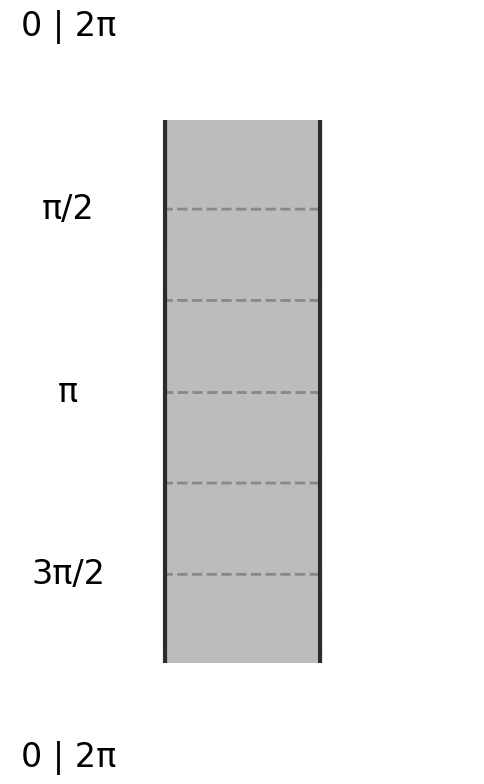

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import imageio_ffmpeg

# Tell Matplotlib exactly where the hidden ffmpeg tool is located
plt.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()

# --- Configuration ---
r_in = .5     # Inner radius
r_out = 2.5    # Outer radius
r_mid = (r_in + r_out) / 2.0
frames = 150

# Colors matching your diagram
color_fill = '#bcbcbc'
color_line = '#2c2c2c'
color_dash = '#888888'
color_mag = '#e038e0'

def get_xy(r, theta, t):
    """
    Transforms polar coordinates (r, theta) into Cartesian (x, y) 
    based on the unwrapping parameter t (0 = circle, 1 = vertical bar).
    """
    # Prevent division by absolute zero at t=1
    t_adj = t * 0.9999
    
    # Calculate the maximum angle and radius of curvature as it flattens
    theta_max = np.pi * (1 - t_adj)
    rho = np.pi * r_mid / theta_max
    
    # Center of curvature
    C_x = rho - r_mid
    
    # Map theta to position along the arc
    s = (theta - np.pi) / np.pi
    alpha = s * theta_max
    
    # Current radius from the center of curvature
    R = rho + (r - r_mid)
    
    # Calculate x and y
    x = C_x - R * np.cos(alpha)
    y = -R * np.sin(alpha)
    
    # Shift everything slightly so the final bar remains centered
    x_shifted = x + t * r_mid
    
    return x_shifted, y

# --- Setup Plot ---
fig, ax = plt.subplots(figsize=(6, 8))
ax.set_aspect('equal')
ax.axis('off') # Hide axes

# Fixed limits to prevent zooming during animation
ax.set_xlim(-6, 6)
ax.set_ylim(-7, 7)

# --- Initialize Plot Elements ---
# 1. The gray annulus (ring)
theta_fill = np.linspace(0, 2*np.pi, 200)
r_poly = np.concatenate([np.full_like(theta_fill, r_out), np.full_like(theta_fill, r_in)])
theta_poly = np.concatenate([theta_fill, theta_fill[::-1]])
poly_fill, = ax.fill([], [], color=color_fill, zorder=1)

# 2. Outer and Inner outlines
line_out, = ax.plot([], [], color=color_line, lw=3, zorder=3)
line_in, = ax.plot([], [], color=color_line, lw=3, zorder=3)

# 3. Gray dashed spokes
spoke_angles = [np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]
spoke_lines = [ax.plot([], [], color=color_dash, lw=2, linestyle='--', zorder=2)[0] for _ in spoke_angles]

# 4. Magenta cut line (splits into two at theta=0 and theta=2pi)
mag_line0, = ax.plot([], [], color=color_mag, lw=4, linestyle='--', zorder=4)
mag_line2, = ax.plot([], [], color=color_mag, lw=4, linestyle='--', zorder=4)

# 5. Text Labels
labels = [
    (0, '0 | 2π'), 
    (np.pi/2, 'π/2'), 
    (np.pi, 'π'), 
    (3*np.pi/2, '3π/2'),
    (2*np.pi, '0 | 2π') # Duplicate 0 for the bottom of the split
]
text_objs = []
for theta, text in labels:
    # Set text slightly outside the outer radius
    txt = ax.text(0, 0, text, fontsize=24, ha='center', va='center', zorder=5)
    text_objs.append((txt, theta))

# --- Updated Animation Logic ---
# Hold at 0 (circle), animate 0 -> 1 (unroll), hold at 1 (bar)
t_seq = np.concatenate([
    np.zeros(15), 
    (1 - np.cos(np.linspace(0, np.pi, 90))) / 2, # Unrolling
    np.ones(45) # Hold the final bar shape
])

def update(frame):
    t = t_seq[frame]
    
    # Update fill
    x_poly, y_poly = get_xy(r_poly, theta_poly, t)
    poly_fill.set_xy(np.column_stack([x_poly, y_poly]))
    
    # Update outlines
    x_out, y_out = get_xy(np.full_like(theta_fill, r_out), theta_fill, t)
    line_out.set_data(x_out, y_out)
    
    x_in, y_in = get_xy(np.full_like(theta_fill, r_in), theta_fill, t)
    line_in.set_data(x_in, y_in)
    
    # Update dashed spokes
    r_spoke = np.linspace(r_in, r_out, 10)
    for line, angle in zip(spoke_lines, spoke_angles):
        x_spoke, y_spoke = get_xy(r_spoke, np.full_like(r_spoke, angle), t)
        line.set_data(x_spoke, y_spoke)
        
    # Update magenta lines
    x_m0, y_m0 = get_xy(r_spoke, np.zeros_like(r_spoke), t)
    mag_line0.set_data(x_m0, y_m0)
    
    x_m2, y_m2 = get_xy(r_spoke, np.full_like(r_spoke, 2*np.pi), t)
    mag_line2.set_data(x_m2, y_m2)
    
    # Update text positions
    for txt, theta in text_objs:
        x_txt, y_txt = get_xy(r_out + 1.25, theta, t)
        txt.set_position((x_txt, y_txt))
        
    return [poly_fill, line_out, line_in, mag_line0, mag_line2] + spoke_lines + [t[0] for t in text_objs]

# --- Generate and Save ---
print("Generating animation. This may take a few seconds...")
ani = animation.FuncAnimation(fig, update, frames=len(t_seq), blit=True)

# Save as a looping GIF
ani.save('circle_to_bar.mp4', writer='ffmpeg', fps=45)
print("Animation saved successfully as 'circle_to_bar.mp4'!")